# Homework 6

TFCB 2024

Due date: Nov 14, 2024

In this homework, we will work through a series of manipulations to analyze a published deep sequencing
dataset using `tidyverse` functions.

In the process, we will learn some new functions in `tidyverse` and apply
them to our data analysis.

For more information about the data used in this homework, see
[this page](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE89183).


In [40]:
library(tidyverse)

## Problem 1

**10 points**

For each of the following functions, provide a <100 character description
(in your own words) and a URL reference.

1. `!`
1. `colnames()`
2. `is.na`
3. `is.numeric`
4. `anti_join`
5. `desc`
6. `dplyr::slice`
7. `dplyr::across`


1. NOT operator that switches the logical value it is used on to its opposite, so !TRUE is FALSE. 
    URL: https://builtin.com/data-science/and-in-r
2. Returns the names of the columns in a data frame. 
    URL: https://www.codecademy.com/resources/docs/r/data-frames/colnames
3. Checks if any cell in a data frame is missing. 
    URL: https://www.rdocumentation.org/packages/base/versions/3.6.2/topics/NA
4. Checks if a value is numeric. 
    URL: https://www.rdocumentation.org/packages/dRiftDM/versions/0.3.3/topics/is_numeric
5. Checks if any rows in one data frame does not exist in a second data frame. 
    URL: https://www.geeksforgeeks.org/r-language/anti-join-in-r/
6. Sorts a vector in descending order. 
    URL: https://dplyr.tidyverse.org/reference/desc.html
7. A function in the package dplyr that can select, duplicate, or delete a row(s) in a data frame. 
    URL: https://dplyr.tidyverse.org/reference/slice.html
8. A function in the package dplyr that can apply a function to many columns in a data frame. 
    URL: https://dplyr.tidyverse.org/reference/across.html
    

## Problem 2

**10 points**

Add a comment above each code line below explaining what the code line does and/or why
that code line is necessary.

Keep each comment to less than 2 lines per line of code and < 80 chars per line.

In [41]:
# load the biomaRT package
library(biomaRt)

# connect to the Ensembl database and select for human genes
mart <- useMart('ensembl', dataset = 'hsapiens_gene_ensembl')

# mart <- useDataset(“hsapiens_gene_ensembl”, mart)

# store gene annotations from Ensembl in a data frame called annotations 
annotations <- getBM(
  # use data set created above 
  mart = mart,
  # retrieve the gene id, hgnc symbol, and ccds id for each gene 
  attributes = c('ensembl_gene_id', 'hgnc_symbol', 'ccds'),
  # remove duplicate rows 
  uniqueRows = TRUE) %>%
  # rename the column ccds to ccds_id for clarity
  rename(ccds_id = `ccds`) %>%
  # drop rows where the column for ccds_id is empty 
  filter(ccds_id != '') %>%
  # display the resulting data frame 
  print()

ERROR: Error in bmRequest(request = request, httr_config = httr_config, verbose = verbose): Not Found (HTTP 404).


In [ ]:
# store gene count table from GEO in a data frame called data
data <- read_tsv("https://ftp.ncbi.nlm.nih.gov/geo/series/GSE89nnn/GSE89183/suppl/GSE89183_Counts.txt.gz") %>%
  # rename the column ENSEMBL gene to ensembl_gene_id for clarity
  rename(ensembl_gene_id = `ENSEMBL gene`) %>%
  # display the resulting data frame
  print()

Rows: 63677 Columns: 15
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr  (1): ENSEMBL gene
dbl (14): CD34_shTSR2_RNA_1, CD34_shTSR2_RNA_2, CD34_shRPL5_RNA_1, CD34_shRP...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


# A tibble: 63,677 × 15
   ensembl_gene_id CD34_shTSR2_RNA_1 CD34_shTSR2_RNA_2 CD34_shRPL5_RNA_1
   <chr>                       <dbl>             <dbl>             <dbl>
 1 ENSG00000000003                48                56                40
 2 ENSG00000000005                 0                 2                 0
 3 ENSG00000000419               880               744              1116
 4 ENSG00000000457               124               113               149
 5 ENSG00000000460               249               262               289
 6 ENSG00000000938                89                64               204
 7 ENSG00000000971               106                86               241
 8 ENSG00000001036               897               613              1487
 9 ENSG00000001084               965              1027              1036
10 ENSG00000001167               721               835               498
# … with 63,667 more rows, and 11 more variables: CD34_shRPL5_RNA_2 <dbl>,
#   CD34_shRPL5_RPF_1 <db

## Problem 3

**10 points**

Using the code below:

1. Convert both axes to `log10` instead of linear scales.
2. Show axis tick labels as 10^0^, 10^1^, 10^2^,10^3^, 10^4^, 10^5^ for both axes.
3. There are too many points overlapping in certain regions. Use a different
`geom_` function to convey to your reader how many overlapping points are present
in each region.

Warning message:
“Transformation introduced infinite values in continuous x-axis”
Warning message:
“Transformation introduced infinite values in continuous y-axis”
Warning message:
“Removed 43031 rows containing non-finite values (stat_bin2d).”


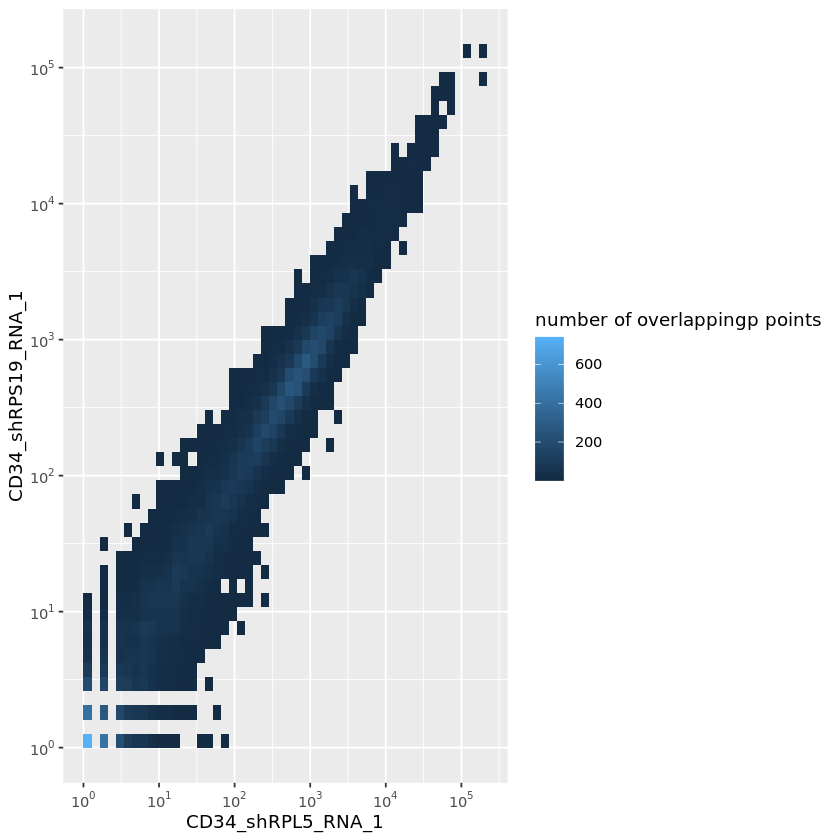

In [ ]:
data %>%
  dplyr::select(CD34_shRPL5_RNA_1, CD34_shRPS19_RNA_1) %>%
  ggplot(aes(x = CD34_shRPL5_RNA_1, y = CD34_shRPS19_RNA_1)) + 
  geom_bin_2d(bins = 50) + 
  scale_x_log10(breaks = 10^(0:5), labels = scales::math_format(10^.x)(0:5)) +
  scale_y_log10(breaks = 10^(0:5), labels = scales::math_format(10^.x)(0:5)) +
  labs(fill = "number of overlappingp points")

**In problems 4 through 6, assign the result of your operation back to the `data`
variable.**

## Problem 4

**10 points**

Write a code cell to select the following columns from the `data` variable you created above and reassign back to `data`.

Columns to select: `ensembl_gene_id`, columns that have either `RPL5`, `RPS19`, or `Luc` in their name.

Instead of listing every column, use [`matches`](https://tidyselect.r-lib.org/reference/starts_with.html) and a succinct [regular expression](https://stringr.tidyverse.org/articles/regular-expressions.html) to select the above columns.

In [ ]:
data <- data %>%
  dplyr::select(ensembl_gene_id, matches("RPL5|RPS19|Luc"))

## Problem 5

**10 points**

Write a code cell to filter the result from Problem 4 to include only rows where each of the 12 numerical columns you selected has 50 counts or more  and reassign back to `data`.
This is a simple way to avoid genes that have very low counts.

You might be tempted to do this step separately for each of the 12 columns, but instead use the `across` function you learned above or the `pivot_longer` function from the class (either way is fine).

In [ ]:
data <- data %>%
  filter(if_all(-ensembl_gene_id, ~ .x >= 50))

## Problem 6

**10 points**

Write a code cell to divide each of the 12 numerical columns by the
corresponding median value for each column
and reassign back to `data`. This median normalization is typically done in
high-throughput experiments after filtering
to normalize for sample-to-sample difference in read depth.

Again, you can write lot less code if you use the `mutate` and `across` function
you learned above.


In [ ]:
data <- data %>%
  mutate(across(-ensembl_gene_id, ~ .x /median(.x)))

## Problem 7

**10 points**

After we do the above filtering and median-normalization, let us calculate
translation efficiency as the average ratio of the RPF and RNA reads for each
treatment condition. Then we calculate how this translation efficiency changes
between target (`rpl5` and `rps19`) and control (`luc`) shRNAs.

The code implementing the above steps is shown below, but it has a few
errors. Correct them.


In [ ]:
lfc <- data %>%
  mutate(mean_rpl5_te = ((CD34_shRPL5_RPF_1 + CD34_shRPL5_RPF_2) /
                            (CD34_shRPL5_RNA_1 + CD34_shRPL5_RNA_2))) %>%
  mutate(mean_rps19_te = ((CD34_shRPS19_RPF_1 + CD34_shRPS19_RPF_2) /
                            (CD34_shRPS19_RNA_1 + CD34_shRPS19_RNA_2))) %>%
  mutate(mean_shluc_te = ((CD34_shLuc_RPF_1 + CD34_shLuc_RPF_2) /
                            (CD34_shLuc_RNA_1 + CD34_shLuc_RNA_2))) %>%
  select(ensembl_gene_id, mean_rpl5_te, mean_rps19_te, mean_shluc_te) %>%
  mutate(lfc_te_rpl5 = log2(mean_rpl5_te / mean_shluc_te),
         lfc_te_rps19 = log2(mean_rps19_te / mean_shluc_te)) %>%
  print()

# A tibble: 4,239 × 6
   ensembl_gene_id mean_rpl5_te mean_rps19_te mean_shluc_te lfc_te_rpl5
   <chr>                  <dbl>         <dbl>         <dbl>       <dbl>
 1 ENSG00000000419        0.919         1.49          1.08       -0.239
 2 ENSG00000001036        1.17          1.11          1.45       -0.316
 3 ENSG00000001084        1.02          1.14          0.853       0.258
 4 ENSG00000001497        1.38          1.04          1.75       -0.338
 5 ENSG00000002549        1.78          1.87          1.50        0.245
 6 ENSG00000002586        0.903         0.825         1.14       -0.331
 7 ENSG00000002834        0.479         0.394         0.519      -0.115
 8 ENSG00000003056        1.87          1.87          1.02        0.882
 9 ENSG00000003393        0.831         1.20          0.462       0.847
10 ENSG00000003402        0.505         0.427         0.344       0.552
# … with 4,229 more rows, and 1 more variable: lfc_te_rps19 <dbl>


## Problem 8

**10 points**

Write code that will create a new dataframe called `mean_lfc` from `lfc`
containing a new column called `avg_lfc`.
`avg_lfc` should be the average of the log2 fold-change in TE (`lfc_te`) upon
knockdown of RPL5 and RPS19.

Then select only the gene id column and the new column that you just created
(this will be your new dataframe `mean_lfc`).


In [ ]:
mean_lfc <- lfc %>%
  mutate(avg_lfc = (lfc_te_rpl5 + lfc_te_rps19) / 2) %>%
  select(ensembl_gene_id, avg_lfc) %>%
    print()

# A tibble: 4,239 × 2
   ensembl_gene_id avg_lfc
   <chr>             <dbl>
 1 ENSG00000000419   0.110
 2 ENSG00000001036  -0.355
 3 ENSG00000001084   0.337
 4 ENSG00000001497  -0.543
 5 ENSG00000002549   0.280
 6 ENSG00000002586  -0.396
 7 ENSG00000002834  -0.256
 8 ENSG00000003056   0.880
 9 ENSG00000003393   1.11 
10 ENSG00000003402   0.431
# … with 4,229 more rows



## Problem 9

**10 points**

Write code to join the `mean_lfc` dataframe with the `annotations` dataframe created
at the top of the document and assign back to `mean_lfc`.


In [ ]:
library(httr)
library(readr)
library(dplyr)

query <- '<?xml version="1.0" encoding="UTF-8"?>
<Query  virtualSchemaName="default" formatter="TSV"
        header="0" uniqueRows="1" datasetConfigVersion="0.6">
  <Dataset name="hsapiens_gene_ensembl" interface="default">
    <Attribute name="ensembl_gene_id"/>
    <Attribute name="hgnc_symbol"/>
    <Attribute name="ccds"/>
  </Dataset>
</Query>'

response <- POST(
  "https://sep2025.archive.ensembl.org/biomart/martservice",
  body = list(query = query),
  encode = "form",
  httr::timeout(180)
)

stop_for_status(response)

annotations <- read_tsv(
  I(content(response, as = "text", encoding = "UTF-8")),
  col_names = c("ensembl_gene_id", "hgnc_symbol", "ccds"),
  show_col_types = FALSE,
  na = c("", "NA")
) %>%
  rename(ccds_id = ccds) %>%
  filter(!is.na(ccds_id), ccds_id != "") %>%
  print()

# A tibble: 35,587 × 3
   ensembl_gene_id hgnc_symbol ccds_id  
   <chr>           <chr>       <chr>    
 1 ENSG00000183753 BPY2        CCDS14800
 2 ENSG00000169953 HSFY2       CCDS35476
 3 ENSG00000169953 HSFY2       CCDS14791
 4 ENSG00000172468 HSFY1       CCDS35475
 5 ENSG00000172468 HSFY1       CCDS14790
 6 ENSG00000176679 TGIF2LY     CCDS14775
 7 ENSG00000182415 CDY2A       CCDS14789
 8 ENSG00000185894 BPY2C       CCDS44030
 9 ENSG00000205916 DAZ4        CCDS55557
10 ENSG00000205916 DAZ4        CCDS94720
# … with 35,577 more rows


In [48]:
mean_lfc <- mean_lfc %>%
    left_join(annotations, by = "ensembl_gene_id")


## Problem 10

**10 points**

1. Write code to select only the bottom 10 genes with the lowest `avg_lfc` and display the gene `symbol`, gene `name` and `avg_lfc` for these genes.
2. Create a figure using `ggplot2` to visualize these results.

Write a few sentences to justify the choices you made when creating your figure.

In [44]:
query_names <- '<?xml version="1.0" encoding="UTF-8"?>
<Query  virtualSchemaName="default" formatter="TSV"
        header="0" uniqueRows="1" datasetConfigVersion="0.6">
  <Dataset name="hsapiens_gene_ensembl" interface="default">
    <Attribute name="ensembl_gene_id"/>
    <Attribute name="description"/>
  </Dataset>
</Query>'

response_names <- POST(
  "https://sep2025.archive.ensembl.org/biomart/martservice",
  body = list(query = query_names),
  encode = "form",
  httr::timeout(180)
)

stop_for_status(response_names)

gene_names <- read_tsv(
  I(content(response_names, as = "text", encoding = "UTF-8")),
  col_names = c("ensembl_gene_id", "description"),
  show_col_types = FALSE,
  na = c("", "NA"),
  quote = ""
)

In [57]:
bottom10 <- mean_lfc %>%
  distinct(ensembl_gene_id,hgnc_symbol,avg_lfc) %>%
  arrange(avg_lfc) %>%
  slice_head(n = 10) %>%
  left_join(gene_names, by = "ensembl_gene_id") %>%
  mutate(name=stringr::str_remove(description, '\\[Source.*')) %>%
  dplyr::select(symbol = hgnc_symbol, name, avg_lfc) %>%
  print()

# A tibble: 10 × 3
   symbol name                                          avg_lfc
   <chr>  <chr>                                           <dbl>
 1 H2AC6  "H2A clustered histone 6 "                      -2.95
 2 H2BC12 "H2B clustered histone 12 "                     -2.79
 3 RPS15  "ribosomal protein S15 "                        -2.27
 4 COX8A  "cytochrome c oxidase subunit 8A "              -2.02
 5 RPL18A "ribosomal protein L18a "                       -2.01
 6 RPLP1  "ribosomal protein lateral stalk subunit P1 "   -2.01
 7 H2AX   "H2A.X variant histone "                        -1.86
 8 RPS26  "ribosomal protein S26 "                        -1.85
 9 APOE   "apolipoprotein E "                             -1.68
10 RPL7A  "ribosomal protein L7a "                        -1.68


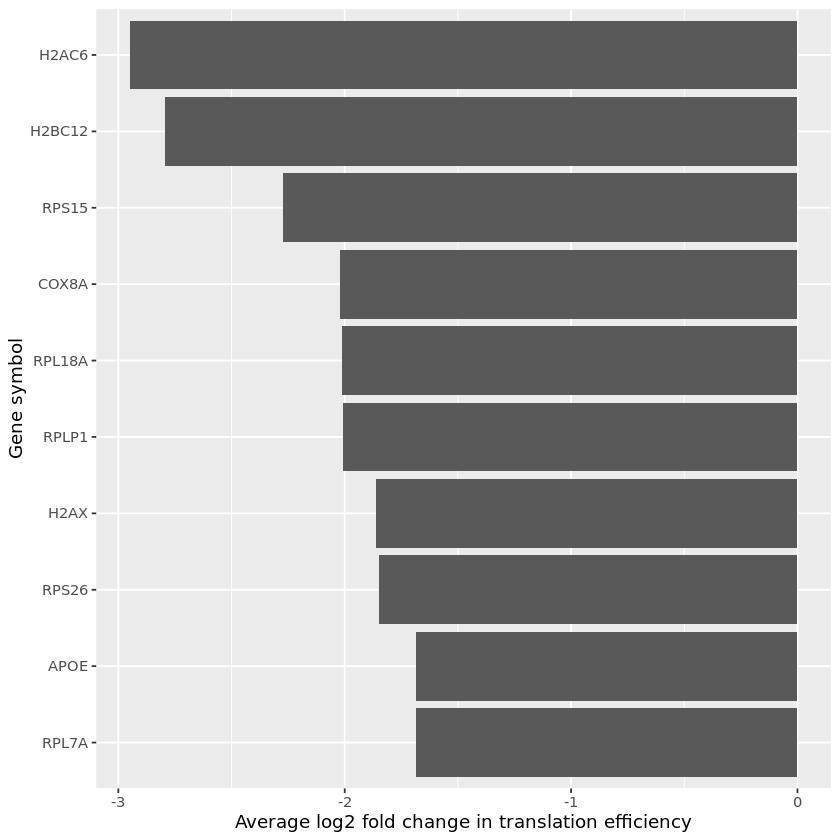

In [ ]:
bottom10 %>%
  ggplot(aes(x = avg_lfc, y = reorder(symbol, -avg_lfc))) +
  geom_col() +
  labs(x = "Average log2 fold change in translation efficiency", y = "Gene symbol")

# I removed duplicates in the data so that the bottom 10 genes are unique. 
# I plotted the bottom 10 genes, which are labeled on the y-axis and each have a bar based on the log2 fold change on the x-axis.  